# FSPM2026 - Modeling Water Fluxes In The Soil-Plant System

## Soil hydraulics with Dumux-rosi

In [2]:
import os
import sys;    
import matplotlib.pyplot as plt  
import numpy as np  
 
import plantbox as pb
import plantbox.visualisation.vtk_plot as vp # for quick vizualisations
from rosi.rosi_richards import RichardsSPnum, RichardsSP  # C++ part (Dumux binding)
from rosi.richards import RichardsWrapper  # Python part  
from rosi.rosi_richards_cyl import RichardsCylFoam  # C++ part (Dumux binding), macroscopic soil model
from rosi.richards_flat import RichardsFlatWrapper  # Python part of cylindrical
import plantbox.functional.van_genuchten as vg

### The Van Genuchten Model

The constitutive equations are described the Van Genuchten model, giving the soil retention curve, hydraulic conductivities or matrix flux potentials. The following script show example parametrisations of various soil types. 

theta_R 0.045 theta_S 0.43 alpha 0.15 n 3 m 0.6666666666666667 Ksat 1000


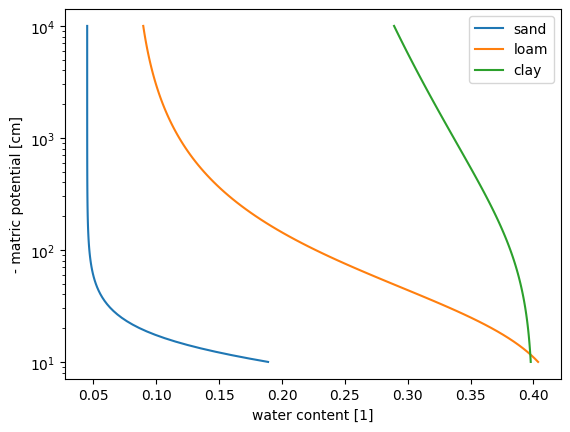

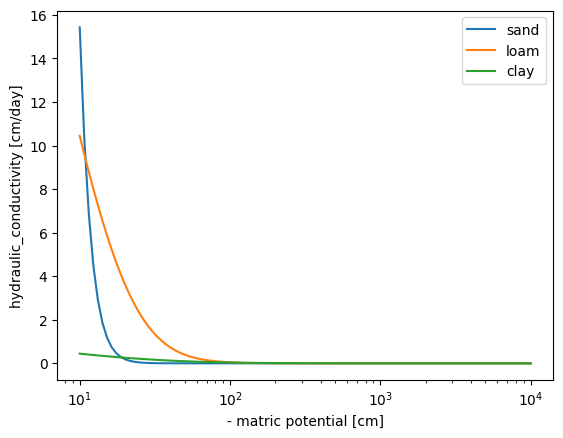

In [3]:
# Define van Genuchten parameters for sand, loam and clay  
# theta_r (-), theta_s (-), alpha (1/cm), n (-), Ks (cm d-1)
sand =  vg.Parameters([0.045, 0.43, 0.15, 3, 1000])
loam =  vg.Parameters([0.08, 0.43, 0.04, 1.6, 50])
clay =  vg.Parameters([0.1, 0.4, 0.01, 1.1, 10])

print("theta_R", sand.theta_R, "theta_S",sand.theta_S, "alpha", sand.alpha,"n",sand.n, 'm',sand.m,'Ksat', sand.Ksat)

vg.plot_retention_curve(sand, label_ = "sand")
vg.plot_retention_curve(loam, label_ = "loam")
vg.plot_retention_curve(clay, label_ = "clay")
plt.legend()
plt.show()
vg.plot_hydraulic_conductivity(sand, label_ = "sand")
vg.plot_hydraulic_conductivity(loam, label_ = "loam")
vg.plot_hydraulic_conductivity(clay, label_ = "clay")
plt.legend()
plt.show()

Therefore, the retention curve relates matric potential and water content and vice versa: 

In [7]:
print(vg.pressure_head(0.2, loam))
print(vg.water_content(-500, loam))
print(vg.water_content(vg.pressure_head(0.2, loam), loam))
    

-143.43429209132952
0.1378237327600404
0.2


## Simulations: 

1. Infiltration into an initially dry soil. This first example is presented in more details.

2. Evaporation from an initially moist soil 

3. Infiltration and evaporation from a multi-layered soil

4. Water uptake by a single root in 1D axisymmetric geometry

### Infiltration into an initially dry soil
In this section, we show an example that reproduces the infiltration example from Schnepf et al. (2023). Water infiltrates into an initially dry soil from the soil surface. Only the vertical water movement is considered. A constant Neumann boundary condition is set at the upper boundary and a free drainage boundary condition is set at the lower boundary. There is an analytical solution for this simple example, which can optionally be plotted for comparison. 

First steps:
- Define the soil hydraulic properties for several soil types and select one for the
current simulation
- Set the simulation time in days
- Set the output time step at which solutions will be saved

In [13]:
# Define van Genuchten parameters for sand, loam and clay  
# theta_r (-), theta_s (-), alpha (1/cm), n (-), Ks (cm d-1)
sand = [0.045, 0.43, 0.15, 3, 1000]
loam = [0.08, 0.43, 0.04, 1.6, 50]
# clay = [0.1, 0.4, 0.01, 1.1, 10]
soil = loam  # Select soil type for simulation  

# simulation time, days
sim_time = 1;  
dt = 720 / (24 * 3600)  # time step [days]   


Set and initialise the Python Wrapper for the solving the Richards equation with DuMu$^x$

In [14]:
s = RichardsWrapper(RichardsSPnum()) 
s.initialize() 

Boundary conditions:
- Set the top boundary condition to "atmospheric"
- Set the bottom boundary condition to "Free drainage"
The arguments are the boundary condition type, in this case "atmospheric", a constant flux value in cm/d, and climate data. The constant flux value (0.5) is ignored in the atmospheric boundary condition, as the value is taken from the climate data. For climate data, two lists are expected, first a list of times (day), second a list of net water flux at the boundary (cm/day). A positive net value means there is infiltration, a negative one means there is evaporation. 

In [15]:
s.setTopBC("atmospheric", 0.5, [[-1., 1.e10], [100., 100.]])  #  [cm/day] atmospheric is with surface run-off   
s.setBotBC("freeDrainage") 

Define the soil grid. In this case, a cubic grid is generated. The arguments define the minimum and maximum values in x, y and z direction, as well as the number of grid cells in each dimension. This definition conveniently allows to define 1D, 2D or 3D problems via the resolution. This example has only 1 soil cell in x and y direction, and $N$ cells vertically. Therefore, this is a 1D simulation that will only consider soil moisture dynamics in the vertical direction.

In [16]:
N = 100
s.createGrid([-5., -5., -200.], [5., 5., 0.], [1, 1, N])  # [cm] N 

No parameter file found. Continuing without parameter file.
No parameter file found. Continuing without parameter file.
Computed bounding box tree with 199 nodes for 100 grid entities in 0.000113504 seconds.
Computed bounding box tree with 199 nodes for 100 grid entities in 4.3994e-05 seconds.


Set homogeneous initial conditions and the hydraulic properties. We also set the critical soil water pressure head at which the Neumann boundary condition at the top switches to Dirichlet boundary condition.

In [17]:
s.setHomogeneousIC(-400.)  # cm pressure head   
s.setVGParameters([soil])
s.initializeProblem()  
s.setCriticalPressure(-15000)  

Pick the positions at which the net flux will be reported. In this case, we pick the center of the surface cell to represent the top boundary and the middle of the bottom cell to represent the bottom boundary.

In [18]:
top_ind = s.pick([0., 0., -0.5])  
bot_ind = s.pick([0., 0., -199.5]) 

We launche the simulation

In [19]:

s.ddt = 1.e-5  # initial dumux time step [days]  

top_new, bot_new, soil_times = [], [], []  

N = int(np.ceil(sim_time / dt)) 
for i in range(0, N):
    t = i * dt  # current simulation time   
    soil_times.append(t)  
    s.solve(dt)  
    velocities = s.getVelocities_()  
    top_new.append(velocities[top_ind])
    bot_new.append(velocities[bot_ind])  

top_new = np.array(top_new)  
bot_new = np.array(bot_new)
soil_times = np.array(soil_times)  



We retrieved the flux vector of the solution and store the values of the top and bottom boundary flux using the index of the correct soil cells. For each position, the net water flux in all 3 directions is given in units of cm/day

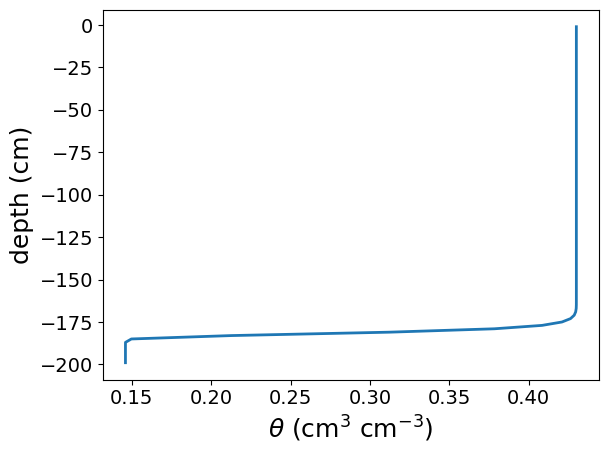

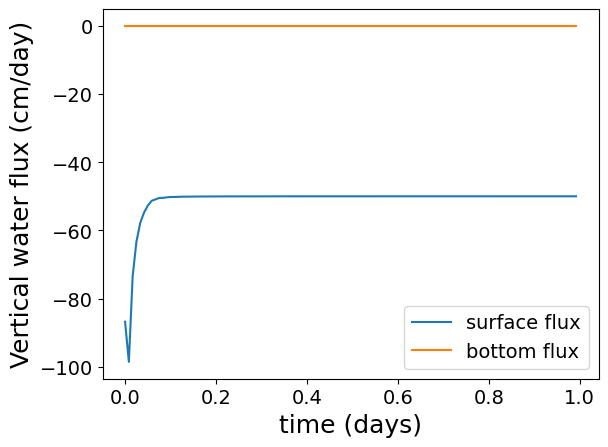

In [20]:

# Extract and plot numerical solution  
points = s.getDofCoordinates()
theta = s.getWaterContent()
plt.figure(0)
plt.plot(theta, points[:, 2], linewidth = 2)
plt.xlabel(r'$\theta$ (cm$^3$ cm$^{-3}$)', fontsize = 18)
plt.ylabel('depth (cm)', fontsize = 18)
plt.xticks(fontsize = 14); plt.yticks(fontsize = 14)
plt.show()  

plt.figure(1)  
plt.plot(soil_times, top_new[:, 2], label = "surface flux")
plt.plot(soil_times, bot_new[:, 2], label = "bottom flux")
plt.xlabel('time (days)', fontsize = 18)
plt.ylabel('Vertical water flux (cm/day)', fontsize = 18)
plt.xticks(fontsize = 14); plt.yticks(fontsize = 14)
plt.legend(fontsize = 14)
plt.show()  

### Evaporation from an initially moist soil 

This example reproduces the evaporation example M2.2 from Schnepf et al. (2023). Water evaporated from the surface of an initially moist soil. Only the vertical water movement is considered. Atmospheric boundary conditions are set at the upper boundary and a free drainage boundary condition is set at the lower boundary. There is an analytical solution for this simple example, which can optionally be plotted for comparison.

Computed bounding box tree with 199 nodes for 100 grid entities in 5.6314e-05 seconds.
Computed bounding box tree with 199 nodes for 100 grid entities in 2.4392e-05 seconds.
initial water volume 1791.9056501866478


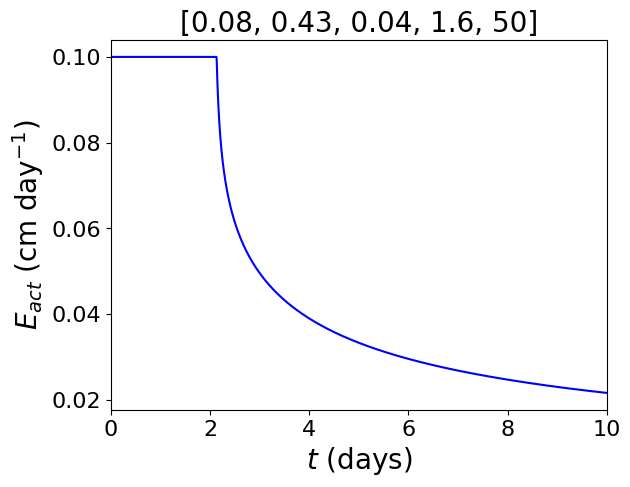

In [15]:
soil = loam  # Select soil type for simulation  
sim_time = 10;  
N = 2000
dt = sim_time / N  # time step [days]  
ic = -200  
evap = -0.1  # [cm/day] Potential transpiration

s = RichardsWrapper(RichardsSP())  
s.initialize()  
s.setTopBC("atmospheric", 0.5, [[0., 1.e10], [evap, evap]])  #  [cm/day]    
# s.setTopBC("flux", evap)  #  [cm/day]
# s.setTopBC("constantPressure", -10000)
s.setBotBC("freeDrainage")  # BC freeDrainage  
NZ = 100 # 1399
s.createGrid([-5., -5., -100.], [5., 5., 0.], [1, 1, NZ])  # [cm]  
# vols = (100. / NZ) * np.ones((NZ,)) * 100.  # cm3
s.setVGParameters([soil])  
s.setHomogeneousIC(ic)  # cm pressure head  
# s.setParameter("Problem.EnableGravity", "false")
s.initializeProblem()  
s.setCriticalPressure(-10000)  
s.setRegularisation(1.e-6, 0.)  
idx_top = s.pickCell([0.0, 0.0, 0.0])  # index to watch surface flux  
initial_water = s.getWaterVolume() 
print("initial water volume", initial_water)
s.ddt = 1.e-5  # initial Dumux time step [days] 
maxDt = 1.  # maximal Dumux time step [days]  

x_, y_ = [], []
for i in range(0, N):  
    s.solve(dt, maxDt)  
    f = s.getNeumann(idx_top)  # f = s.getSolutionHeadAt(idx_top)   
    #   current_water = s.getWaterVolume()
    #   f = (initial_water - current_water) / dt / 1.e2
    #   print(current_water, f)
    #   initial_water = current_water
    x_.append(s.simTime)
    y_.append(f)  

# Extract and plot numerical solution
plt.plot(x_, y_, 'b') 
plt.ylabel('$E_{act}$ (cm day$^{-1}$)', fontsize = 20)
plt.xlim(0, 10)
plt.title(soil, fontsize = 20)
plt.xlabel('$t$ (days)', fontsize = 20)
plt.ylabel('$E_{act}$ (cm day$^{-1}$)', fontsize = 20)
plt.tick_params(axis = 'both', which = 'major', labelsize = 16)
plt.show()  


### Infiltration and evaporation from a multi-layered soil

This example builds on the infiltration and evaporation problem M2.1 and M2.2 from Schnepf et al. (2023) and extends the simulation to a multi-layered soil profile at the Field Minirhizotron Facilities Selhausen (\url{https://www.fz-juelich.de/en/ibg/ibg-3/research-groups/modelling-terrestrial-systems/soil-root-systems-and-rhizosphere-processes/field-minirhizotron-facilities}).
The hydraulic properties of the soil profile are taken from Bauer et al. (2011, table 3, \url{https://doi.org/10.1007/s10533-011-9583-1}).
The Richards equations is solved to simulate water infiltration over 1 day into an initially dry soil followed by evaporation over 2 days. Only the vertical water movement is considered. A Neumann boundary condition is set at the upper boundary and a free drainage boundary condition is set at the lower boundary.

Computed bounding box tree with 59 nodes for 30 grid entities in 3.4431e-05 seconds.
Computed bounding box tree with 59 nodes for 30 grid entities in 1.3631e-05 seconds.
***** external time step 0.008333333333333333  d, simulation time 0.008333333333333333 d, internal time step 0.0020207345920138873 d
***** external time step 0.008333333333333333  d, simulation time 0.09166666666666666 d, internal time step 0.0017722561507270266 d
***** external time step 0.008333333333333333  d, simulation time 0.175 d, internal time step 0.0012702238864568944 d
***** external time step 0.008333333333333333  d, simulation time 0.25833333333333336 d, internal time step 0.0009007035062119394 d
***** external time step 0.008333333333333333  d, simulation time 0.3416666666666667 d, internal time step 0.0009007035062119394 d
***** external time step 0.008333333333333333  d, simulation time 0.425 d, internal time step 0.0009007035062119394 d
***** external time step 0.008333333333333333  d, simulation time 

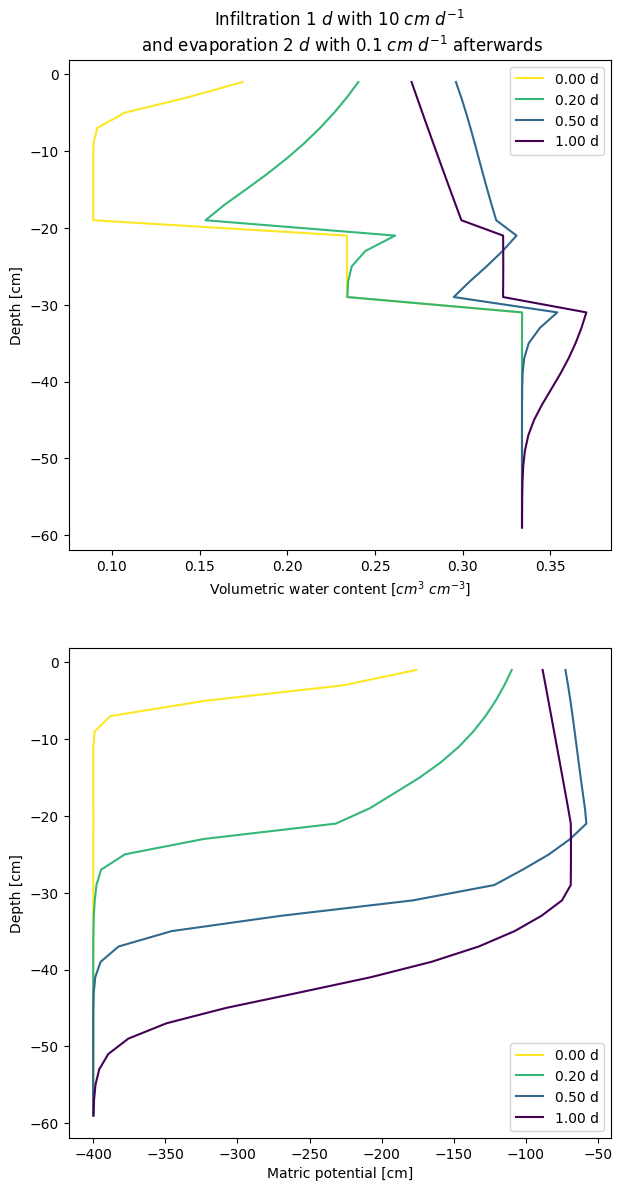

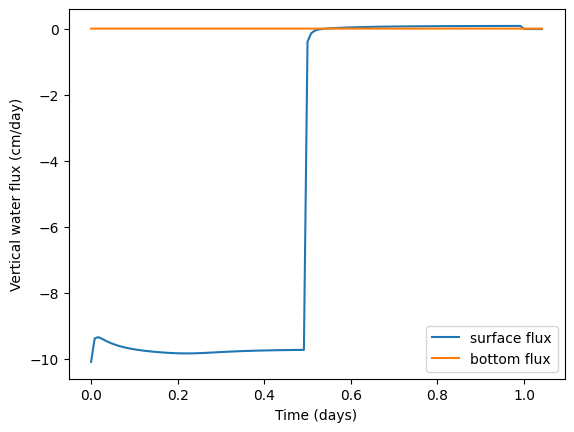

In [5]:
# Define Mualem van Genuchten parameters for Selhausen soil profile according to Bauer et al. (2011, table 3, \url{https://doi.org/10.1007/s10533-011-9583-1}) |\label{l61ies:genuchten_a}|
# theta_r (-), theta_s (-), alpha (1/cm), n (-), Ks (cm d-1)
l1 = [0.008, 0.389, 0.012, 1.97, 91.68]  # 0-20 cm 
l2 = [0.008, 0.389, 0.023, 1.23, 63.36]  # 20-30 cm
l3 = [0.008, 0.389, 0.01, 1.1, 10]  # 30-60 cm

soil = [l1, l2, l3] # Combine the hydraulic conductivity vectors from all soil layers to define soil type for simulation  
sim_time = 1.05  # 3.05
dt = 720 / (24 * 3600)  # time step [days] # 0.05

# Solve the Richards equation using the Python wrapper of dumux-rosi
s = RichardsWrapper(RichardsSPnum())  
s.initialize()  #
s.setTopBC("atmospheric", 0.5, [[ 0., 0.5,  0.5,   1., 1., 1.e6], 
                                [10., 10., -0.1, -0.1, 0., 0.]])  #  [cm/day] atmospheric is with surface run-off  
s.setBotBC("freeDrainage") 
N = 30   # use a fine grid resolution of 1 mm per grid point in z direction 
s.createGrid([-5., -5., -60.], [5., 5., 0.], [1, 1, N])  # [cm] N   
# define soil layers
layers_ID = [3, 3, 2, 2, 1, 1]  
layers_pos = [-60.,-30., -30, -20, -20, 0] 
s.setLayersZ(layers_ID, layers_pos)
s.setHomogeneousIC(-400.)  # cm pressure head   
s.setVGParameters(soil) 
s.initializeProblem()  
s.setCriticalPressure(-15000)  
s.ddt = 1.e-5  # initial dumux time step [days]

top_ind = s.pick([0., 0., -0.5])
bot_ind = s.pick([0., 0., -59.5])  
top_new, bot_new, soil_times = [], [], []

N = int(np.ceil(sim_time / dt))  
z_, x_, h_ = [], [], []  # initialize solution vectors
import timeit; wall_iteration = timeit.default_timer()
for i in range(0, N):
    s.ddt = 1.e-5  # initial dumux time step [days]
    t = i * dt  # current simulation time
    soil_times.append(t)
    s.solve(dt)
    if i % 10 == 0:
        print("***** external time step", dt, " d, simulation time", s.simTime, "d, internal time step", s.ddt, "d")

    velocities = s.getVelocities_()
    top_new.append(velocities[top_ind])
    bot_new.append(velocities[bot_ind])

    points = s.getDofCoordinates()  # coordinates
    theta = s.getWaterContent()  # volumetric water content
    h = s.getSolutionHead()  # matric potential [cm]
    z_.append(points[:, 2])
    x_.append(theta)
    h_.append(h)
wall_iteration = timeit.default_timer() - wall_iteration
top_new = np.array(top_new)
bot_new = np.array(bot_new)
soil_times = np.array(soil_times)

sel_idx = np.searchsorted(soil_times, [0., 0.2, 0.5, 1.]) #, 1.2, 2., 3.]) # define output times

# Plot solutions 
fig1, axs = plt.subplots(2, 1, figsize = (7, 14))
cmap = plt.cm.viridis  # or 'plasma', 'cividis', 'Blues'
cols = cmap(np.linspace(0, 1, len(sel_idx)))
cols = cols[::-1]
for ii, i in enumerate(sel_idx):
    axs[0].plot(x_[i], z_[i], color = cols[ii], label = f'{soil_times[i]:.2f} d')
    axs[1].plot(h_[i], z_[i], color = cols[ii], label = f'{soil_times[i]:.2f} d')

axs[0].set_title("Infiltration 1 $d$ with 10 $cm$ $d^{-1}$ \n and evaporation 2 $d$ with 0.1 $cm$ $d^{-1}$ afterwards")
axs[0].set_xlabel('Volumetric water content [$cm^{3}$ $cm^{-3}$]')
axs[0].set_ylabel('Depth [cm]')
axs[1].set_xlabel('Matric potential [cm]')
axs[1].set_ylabel('Depth [cm]')
axs[0].legend(loc = "best")
axs[1].legend(loc = "best")

plt.show()

plt.figure(1)
plt.plot(soil_times, top_new[:, 2], label = "surface flux")
plt.plot(soil_times, bot_new[:, 2], label = "bottom flux")
plt.xlabel('Time (days)')
plt.ylabel('Vertical water flux (cm/day)')
plt.legend()
plt.show()


### Water uptake by a single root in 1D axisymmetric geometry



area per cell [cm2] [[0.0014192 ]
 [0.00302198]
 [0.00643488]
 [0.01370219]
 [0.0291769 ]
 [0.06212813]
 [0.13229317]
 [0.28169983]
 [0.59984045]]
Distance from root surface [cm] [[0.02459233]
 [0.03588593]
 [0.05236593]
 [0.07641408]
 [0.11150593]
 [0.16271312]
 [0.23743632]
 [0.34647486]
 [0.50558748]]

domain water volume 2.4618629269006114 cm3/cm  =  0.0024618629269006114 l/cm
water content to water volume 2.4618629269006114 cm3/cm
 -- Using the default temperature of 293.15 in the entire domain. Overload temperatureAtPos() in your spatial params class to define a custom temperature field.Or provide the preferred domain temperature via the SpatialParams.Temperature parameter.
domain water volume 1.0964707722756415 cm3/cm  =  0.0010964707722756414 l/cm
change in water volume -1.3653921546249699 cm3/cm =  -0.00136539215462497 l/cm


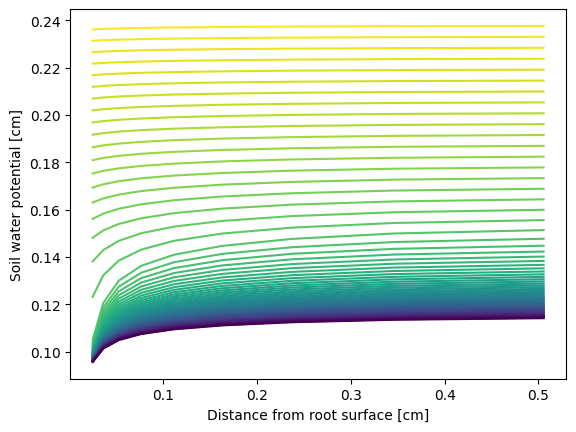

In [6]:
def sinusoidal(t):
    """ sinusoidal function (used for transpiration) (integral over one day is 1)"""
    return np.sin(2. * np.pi * np.array(t) - 0.5 * np.pi) + 1.


def plot_profile(cc, h, depth = -100.):
    """ shows soil matric potential profile over time"""
    fig, ax1 = plt.subplots()
    n = len(h) // 1
    cmap = plt.cm.viridis  # or 'plasma', 'cividis', 'Blues'
    cols = cmap(np.linspace(0, 1, n))
    cols = cols[::-1]
    for i in range(0, n):
        ax1.plot(cc, h[i * 1], color = cols[i])
    ax1.set_ylabel("Soil water potential [cm]")
    ax1.set_xlabel("Distance from root surface [cm]")


""" Soil """
s = RichardsFlatWrapper(RichardsCylFoam())  # water & single solute
logbase = 0.5
NC = 10  # [1] spatial resolution (1D model)
a_in = 0.02  # cm
a_out = 0.6  # cm
points = np.logspace(np.log(a_in) / np.log(logbase), np.log(a_out) / np.log(logbase), NC, base = logbase)
soil = [0.078, 0.43, 0.036, 1.56, 24.96]  # hydrus loam
s.initialize()
s.createGrid1d(points)
s.setVGParameters([soil])

""" Inital conditions """
s.setHomogeneousIC(-100.)  # [cm] homogeneous pressure head

""" Boundary conditions """
RS_Uptake_Wmax = 1.  # [cm/day]
s.setOuterBC("fluxCyl", 0.)  #  [cm/day] Neumann boundary condition
s.setInnerBC("fluxCyl", 0.)

""" Initialze problem """  # |\label{l63:init_start}|
s.setParameter("Newton.EnableAbsoluteResidualCriterion", "True")
s.setParameter("Newton.MaxAbsoluteResidual", "1.e-10")
s.setParameter("Newton.SatisfyResidualAndShiftCriterion", "True")
s.setParameter("Newton.EnableChop", "True")
s.initializeProblem()
wilting_point = -10000
s.setCriticalPressure(wilting_point)
s.ddt = 1e-4  # [day] initial Dumux time step

""" Simulation loop """
simtime = 3
dt = 3600. / (24.*3600)
cc = np.array(s.getCellCenters())  # [cm]
points = np.array(s.getPoints())  # [cm] cell faces
area = np.pi * (points[1:] ** 2 - points[:-1] ** 2)  # [cm2] area of each cell
print("area per cell [cm2]", area)
print("Distance from root surface [cm]", cc)
theta = np.array(s.getWaterContent())
volume0 = np.sum(np.multiply(theta , area))
print("\ndomain water volume", volume0, "cm3/cm  = ", volume0 / 1000, "l/cm")
print("water content to water volume", volume0 , "cm3/cm")

N = int(np.ceil(simtime / dt))
h, theta = [], []  # results

for i in range(0, N):
    t = i * dt  # current simulation time
    #print(t, "days")

    s.setInnerBC("fluxCyl", -RS_Uptake_Wmax)  # [cm/day]; * sinusoidal(t)
    s.solve(dt)
    h.append(s.getSolutionHead())  # [cm]
    theta.append(s.getWaterContent())  # [1]

volumef = np.sum(np.multiply(theta[-1] , area))  # |\label{l63:vol}|
print("domain water volume", volumef, "cm3/cm  = ", volumef / 1000., "l/cm")  # |\label{l63:results}|
print("change in water volume", volumef - volume0, "cm3/cm = ", 1.e-3 * (volumef - volume0), "l/cm")

plot_profile(cc, theta)
plt.show()
